<a href="https://colab.research.google.com/github/aksshaya22/Akss_1/blob/main/book/1_basics/Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
short_title: Exercises
execute:
  skip: true
downloads:
  - url: https://colab.research.google.com/github/mibur1/psy300/blob/main/book/1_basics/Exercises.ipynb
    title: Open in Colab
  - file: Exercises.ipynb
    title: Download notebook
---

# 🏋️ Exercises

## Exercise 1: Linear Regression Recap

Please implement regression models using `statsmodels`, `sklearn`, and `numpy`. Which degree of polynomial is most suited for the synthetic data provided in the code cell below?

Plot the resulting regression models.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Generate synthetic data
n_samples = 100
X = np.linspace(-2, 2, n_samples).reshape(-1, 1)
y = X**2 + np.random.normal(scale=0.5, size=X.shape)

# TODO: Statsmodels
...

# TODO: Numpy
...

# TODO: Scikit-learn
...

# TODO: Plot the predictions
...

## Exercise 2: Bias-variance Tradeoff

To get a better understanding about the bias-variance tradeoff, we will fit polynomial regression models to synthetic data from a known function $y=sin(x)$.

Please perform the following tasks:

1. Visualize the data. Which model do you think would be optimal?
2. Split the data into a training set (70%) and testing set (30%)
3. Fit polynomial regression models for degrees 1 to 15
4. Plot the errors against the model degrees

*Hint: You can split the data with the `train_test_split()` function from `sklearn.model_selection`.*

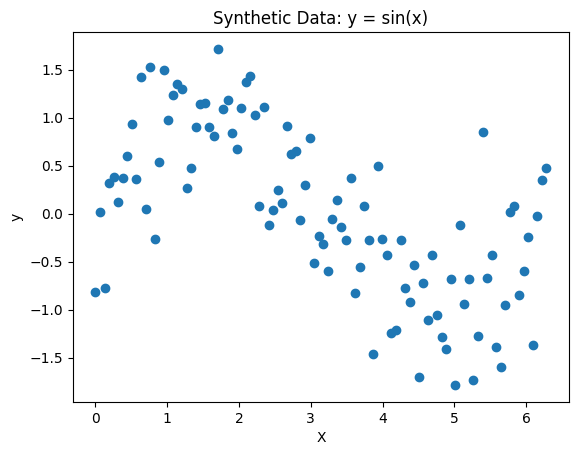

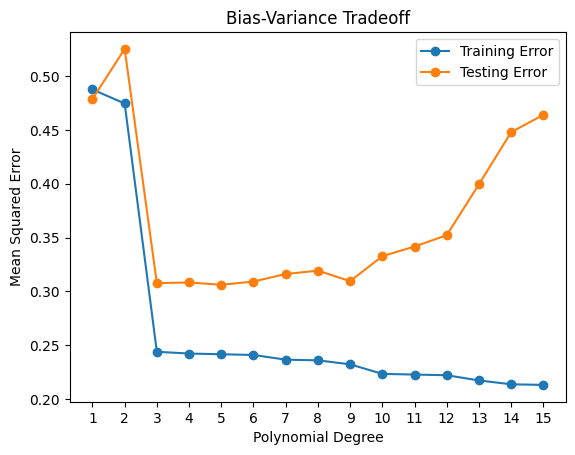

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Generate synthetic data
np.random.seed(55)
n_samples = 100
X = np.linspace(0, 2*np.pi, n_samples).reshape(-1, 1)  # Reshape for sklearn
y = np.sin(X) + np.random.normal(scale=0.5, size=X.shape)

# 1. TODO: Visualize the data
plt.scatter(X,y)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Synthetic Data: y = sin(x)')
plt.show()

# 2. TODO: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=55)

# 3. TODO: Fit polynomial regression models for degrees 1 to 15
degrees = range(1, 16)
train_errors = []
test_errors = []

for degree in degrees:
  poly = PolynomialFeatures(degree=degree)
  X_train_poly = poly.fit_transform(X_train)
  X_test_poly = poly.transform(X_test)

  model = LinearRegression()
  model.fit(X_train_poly, y_train)

  y_train_pred = model.predict(X_train_poly)
  y_test_pred = model.predict(X_test_poly)

  train_error = mean_squared_error(y_train, y_train_pred)
  test_error = mean_squared_error(y_test, y_test_pred)

  train_errors.append(train_error)
  test_errors.append(test_error)

# 4. TODO: Plot the training and testing errors against polynomial degree
plt.plot(degrees, train_errors, marker="o", label="Training Error")
plt.plot(degrees, test_errors, marker="o", label="Testing Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Bias-Variance Tradeoff")
plt.xticks(degrees)
plt.legend()
plt.show()

## Exercise 3: Resampling Methods

The dataset we are using for the exercise is the [California Housing Dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html). It contains 20640 samples and 8 features. In this dataset, we have information regarding the demography (income, population, house occupancy) in the districts, the location of the districts (latitude, longitude), and general information regarding the house in the districts (number of rooms, number of bedrooms, age of the house). Since these statistics are at the granularity of the district, they corresponds to averages or medians.

Familiarize yourself with the dataset by exploring the documentation and looking at the data. What are the features and target?

In [ ]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df = data.frame
...

Let’s have a quick look at the distribution of these features by plotting their histograms.

In [ ]:
# TODO: Plot histograms
...

1. Prepare the data for cross validation. This will require you to have a variable (e.g. `X`) for the features and a variable for the target (e.g. `y`).
2. Set up a k-fold cross validation for a linear regression
    - Choose an appropriate k
    - Define the model
    - Perform cross validation
    - Use the mean squared error (MSE) to assess model performance

*Hints:*
- *For 1: You can achieve this by e.g. creating them from the DataFrame, or by using the `return_X_y` parameter on the [`fetch_california_housing()`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html) function*
- *For 2: You can use the `LinearRegession()` model from sklearn. You can further evaluate the model and specify the (negative) MSE as a performance measure in `cross_val_score()`*

In [ ]:
# TODO: Prepare data
...

In [ ]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

# TODO: Implement CV
...

## Exercise 4: LOOCV

1. Use LOOCV and compare the average MSE
2. Get the minimum and maximum MSE value. Discuss the range!
3. Plot the MSE values in a histogram (the x-range should be from 0 to 6)
4. Calculate the median MSE and discuss if it might be a more appropriate measure than the mean

*Hints*
- *As we have 20640 observations this will probably take more than a minute to calculate. Feel free to subset the number of observations to e.g. 5000.*

In [ ]:
# TODO: Implement LOOCV
...